In [1]:
# Experiment 06 — Deutsch–Jozsa Algorithm

In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

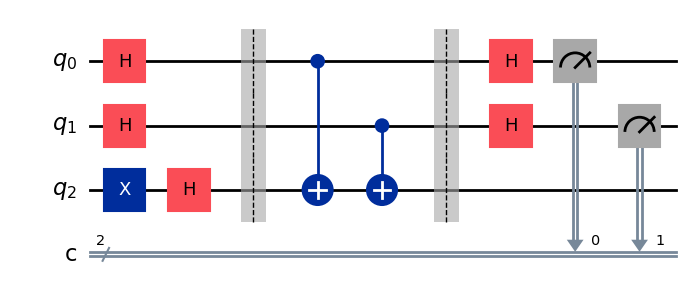

In [3]:
# Create a circuit with 2 input qubits and 1 output qubit
qc = QuantumCircuit(3, 2)

# Prepare the output qubit in |1>
qc.x(2)

# Apply Hadamard gates to all qubits
qc.h([0, 1, 2])

qc.barrier()

# Apply a balanced oracle
qc.cx(0, 2)
qc.cx(1, 2)

qc.barrier()

# Apply Hadamard gates to the input qubits
qc.h([0, 1])

# Measure the input qubits
qc.measure([0, 1], [0, 1])

# Display the circuit
display(qc.draw("mpl"))

Balanced Function: {'11': 1024}


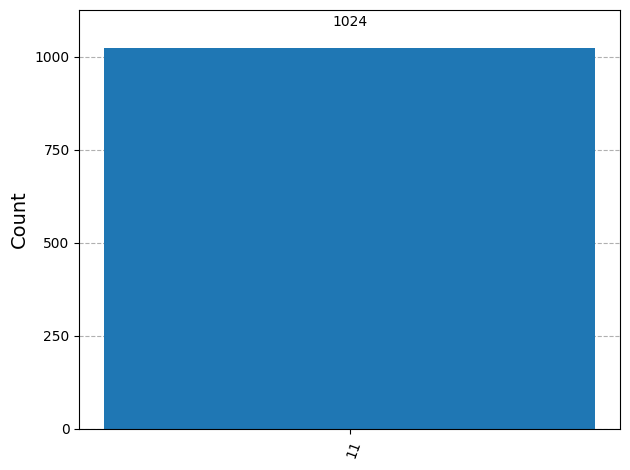

In [4]:
# Run the balanced oracle circuit
simulator = AerSimulator()

result = simulator.run(
    transpile(qc, simulator),
    shots=1024,
    seed_simulator=42
).result()

balanced_counts = result.get_counts()

print("Balanced Function:", balanced_counts)

# Display the measurement histogram
display(plot_histogram(balanced_counts))

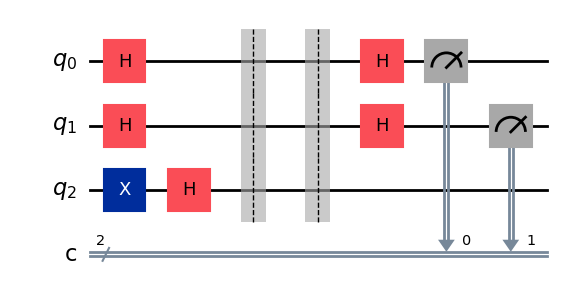

In [5]:
# Create a circuit for a constant function
qc_constant = QuantumCircuit(3, 2)

# Prepare the output qubit
qc_constant.x(2)

# Apply Hadamard gates
qc_constant.h([0, 1, 2])

qc_constant.barrier()

# Constant-zero oracle leaves the qubits unchanged
qc_constant.barrier()

# Apply Hadamard gates to the input qubits
qc_constant.h([0, 1])

# Measure the input qubits
qc_constant.measure([0, 1], [0, 1])

# Display the circuit
display(qc_constant.draw("mpl"))

Constant Function: {'00': 1024}


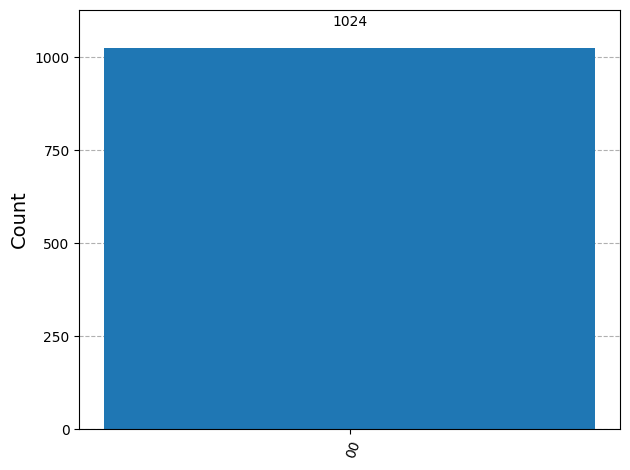

In [6]:
# Run the constant oracle circuit
result = simulator.run(
    transpile(qc_constant, simulator),
    shots=1024,
    seed_simulator=42
).result()

constant_counts = result.get_counts()

print("Constant Function:", constant_counts)

# Display the measurement histogram
display(plot_histogram(constant_counts))

In [7]:
# Identify the function from the measurement results
def identify_function(counts):
    if set(counts) == {"00"}:
        return "Constant"
    return "Balanced"

print("First Oracle:", identify_function(balanced_counts))
print("Second Oracle:", identify_function(constant_counts))

First Oracle: Balanced
Second Oracle: Constant
